# 12 · Может ли ML улучшить интерполяцию Эрмита?

**Вопрос:** дает ли обучаемая поправка пользу сверх сильного метода без обучения?

Сохраняем 41 обучающий рейс и 8 validation-рейсов из 11. Признаки – те же 19 характеристик доступных концов. Меняется проверочная поправка: теперь это отличие скрытого наблюдения от Эрмита, а не от прямой линии.

Регуляризация выбирается только по validation 25 ноября. Проверка выполняется на заранее назначенных новых датах **9 и 16 декабря 2019 года**. День 2 декабря, уже просмотренный в 11, в обучение и проверку не включаем. Сравниваем чистый Эрмит, сохраненную модель 11 и Эрмит с обучаемой поправкой. Изменения методов после просмотра новых ошибок не выполняем.

In [1]:
# Подключаем библиотеки и проверяем целостность модели 11
from pathlib import Path
import contextlib
import io
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
sys.path.insert(0,str(study/'scripts'))
from evaluate_hidden_points import main as evaluate_baselines
from audit_c40_radial_cases import ellipsoid_distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
plan = json.loads((study/'reports/12_hermite_protocol.json').read_text(encoding='utf8'))
plan11 = json.loads((study/'reports/11_expanded_protocol.json').read_text(encoding='utf8'))
plan['old_model_sha256'] = plan11['old_model_sha256']
model11_path = study/'data/expanded_training/11_ridge_model.npz'
assert hashlib.sha256(model11_path.read_bytes()).hexdigest() == plan['model11_sha256']
model11 = np.load(model11_path,allow_pickle=False)
old_split = json.loads((study/'reports/08_ml_protocol.json').read_text(encoding='utf8'))['split']
small_flights = [f for f,part in old_split.items() if part == 'train']
display(plan)

{'version': '12-v1',
 'train_days': ['2019-11-04', '2019-11-11', '2019-11-18'],
 'validation_day': '2019-11-25',
 'test_days': ['2019-12-09', '2019-12-16'],
 'train_source': 'same 41 flights as 11, validation same 8 flights',
 'features': 'same 19 endpoint features as 08-11',
 'target': 'observed local position minus cubic Hermite local position',
 'alphas': [0.1, 1.0, 10.0, 100.0, 1000.0],
 'selection_metric': 'macro mean WGS84 validation error, equal flight weights',
 'selection': 'first 30 chronological eligible EGCC/EPWA cases, hour 22 UTC',
 'model11_sha256': '77a832f74fbb1c84ff422a8f823e44b1d8cf8c64fc4550ace42b96c9739e703a',
 'old_model_sha256': '595cbe06edbf32c7fdcc83f3914be436b60978d0468e2df0e0230f60ee92443b'}

## 1. Проверяем даты, происхождение данных и разделение

Подготовительные скрипты только получают наблюдения. Здесь виден состав каждого дня, число целей и проверки контрольных сумм. Общие правила пригодности и скрытия точек остаются прежними: воздушное состояние, возраст позиции 0–2 секунды, исходная сетка 10 секунд, интервалы 20–120 секунд.

In [2]:
# Формируем список источников с заранее назначенными ролями
datasets = [
    ('2019-10-21','train',study/'data/public_pilot/EPWA_control_geometry.csv',
     study/'data/public_pilot/07_hidden_point_errors.csv',None),
    ('2019-10-28','train',study/'data/external_day/external_geometry.csv',
     study/'data/external_day/10_external_hidden_point_errors.csv','10_external')]
for day in plan['train_days']+[plan['validation_day']]+plan['test_days']:
    part = 'train' if day in plan['train_days'] else ('validation' if day == plan['validation_day'] else 'test')
    folder = study/f'data/expanded_training/{day}' if day not in plan['test_days'] else study/f'data/hermite_validation/{day}'
    prefix = ('12_' if day in plan['test_days'] else '11_')+day
    datasets.append((day,part,folder/'external_geometry.csv',folder/f'{prefix}_hidden_point_errors.csv',prefix))
frames, baseline_frames, provenance = [], [], []
split, flight_day = {}, {}
for day,part,path,error_path,prefix in datasets:
    frame = pd.read_csv(path)
    if day == '2019-10-21':
        frame = frame[frame.case_flight_id.isin(small_flights)].copy()
        old_audit = json.loads((study/'reports/07_hidden_point_audit.json').read_text(encoding='utf8'))
        assert hashlib.sha256(path.read_bytes()).hexdigest() == old_audit['source_sha256']
    else:
        manifest = json.loads((study/f'reports/{prefix}_download.json').read_text(encoding='utf8'))
        assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest['selected_sha256']
    assert pd.to_datetime(frame.time,unit='s',utc=True).dt.strftime('%Y-%m-%d').eq(day).all()
    # Для новых дат применяем неизменные интервалы и критерии пригодности
    if day in plan['train_days']+[plan['validation_day']]+plan['test_days']:
        if not error_path.exists() or not (study/f'reports/{prefix}_hidden_point_audit.json').exists():
            with contextlib.redirect_stdout(io.StringIO()):
                evaluate_baselines(path,prefix=prefix)
        cached = json.loads((study/f'reports/{prefix}_hidden_point_audit.json').read_text(encoding='utf8'))
        assert cached['source_sha256'] == hashlib.sha256(path.read_bytes()).hexdigest()
        assert cached['gaps_s'] == [20,30,60,120] and cached['max_position_age_s'] == 2
    errors = pd.read_csv(error_path)
    errors = errors[errors.flight_id.isin(frame.case_flight_id.unique())].copy()
    for flight in frame.case_flight_id.unique():
        assert flight not in split, 'Повтор идентификатора между датами'
        split[flight],flight_day[flight] = part,day
    frames.append(frame)
    baseline_frames.append(errors)
    provenance.append({'Дата':day,'Часть':part,'Рейсов':frame.case_flight_id.nunique(),
                       'Наблюдений':len(frame),'Целей':len(errors)//3})
source = pd.concat(frames,ignore_index=True)
baseline_errors = pd.concat(baseline_frames,ignore_index=True)
display(pd.DataFrame(provenance))
# Проверяем непересечение дат обучения, выбора модели и проверки
assert not set(plan['train_days']+['2019-10-21','2019-10-28']).intersection([plan['validation_day']]+plan['test_days'])

,Дата,Часть,Рейсов,Наблюдений,Целей
0,2019-10-21,train,6,753,11277
1,2019-10-28,train,10,1359,21727
2,2019-11-04,train,7,920,14452
3,2019-11-11,train,6,767,11999
4,2019-11-18,train,12,1442,22419
5,2019-11-25,validation,8,935,14581
6,2019-12-09,test,7,852,13188
7,2019-12-16,test,8,977,15323


## 2. Готовим признаки без скрытых координат

Признаки используют позиции, скорости, направления и свежесть двух доступных концов, а также известное время цели. Скрытые координаты используются только в ответе. Все методы проверяются на одинаковых пригодных целях.

In [3]:
# Берем точно те же цели, которые сравнивались в эксперименте 07
key = ['flight_id','gap_s','left_time','target_time']
tasks = baseline_errors[baseline_errors.method.eq('linear_lat_lon')][key].copy()
assert not tasks.duplicated(key).any()
observed = source.rename(columns={'case_flight_id':'flight_id'})
assert not observed.duplicated(['flight_id','time']).any()
tasks['right_time'] = tasks.left_time+tasks.gap_s
# Присоединяем доступные концы отдельно от скрытого ответа
for role,time_col in [('a','left_time'),('b','right_time'),('target','target_time')]:
    fields = ['flight_id','time','lat','lon']
    if role != 'target':
        fields += ['velocity','heading','lastposupdate']
    renamed = observed[fields].rename(columns={c:f'{role}_{c}' for c in fields if c != 'flight_id'})
    tasks = tasks.merge(renamed,left_on=['flight_id',time_col],right_on=['flight_id',f'{role}_time'],validate='many_to_one')
tasks['part'] = tasks.flight_id.map(split)
w = (tasks.target_time-tasks.left_time)/tasks.gap_s
duration = tasks.gap_s
# Линейная интерполяция определяется только доступными концами
lon_delta = (tasks.b_lon-tasks.a_lon+180)%360-180
linear_lat = tasks.a_lat+w*(tasks.b_lat-tasks.a_lat)
linear_lon = tasks.a_lon+w*lon_delta
east_scale = 111320*np.cos(np.radians((tasks.a_lat+tasks.b_lat)/2))
north_scale = 111200
east = lon_delta*east_scale
north = (tasks.b_lat-tasks.a_lat)*north_scale
ha,hb = np.radians(tasks.a_heading),np.radians(tasks.b_heading)
va_e,va_n = tasks.a_velocity*np.sin(ha),tasks.a_velocity*np.cos(ha)
vb_e,vb_n = tasks.b_velocity*np.sin(hb),tasks.b_velocity*np.cos(hb)
curve = w*(1-w)*duration
# Кинематические подсказки используют только скорость и направление концов
features = pd.DataFrame({'gap_s':duration,'fraction':w,'curve_time_s':curve,
    'speed_a':tasks.a_velocity,'speed_b':tasks.b_velocity,
    'heading_a_sin':np.sin(ha),'heading_a_cos':np.cos(ha),
    'heading_b_sin':np.sin(hb),'heading_b_cos':np.cos(hb),
    'age_a':tasks.a_time-tasks.a_lastposupdate,'age_b':tasks.b_time-tasks.b_lastposupdate,
    'east_span':east,'north_span':north,
    'forward_residual_e':va_e*w*duration-w*east,
    'forward_residual_n':va_n*w*duration-w*north,
    'backward_residual_e':(1-w)*east-vb_e*(1-w)*duration,
    'backward_residual_n':(1-w)*north-vb_n*(1-w)*duration,
    'velocity_change_e':(vb_e-va_e)*curve,'velocity_change_n':(vb_n-va_n)*curve})
# Координаты скрытых точек появляются только в целевой поправке
target = np.column_stack([((tasks.target_lon-linear_lon+180)%360-180)*east_scale,
                          (tasks.target_lat-linear_lat)*north_scale])
usable = np.isfinite(features).all(axis=1) & np.isfinite(target).all(axis=1)
display(tasks.assign(usable=usable).groupby('part').agg(total=('flight_id','size'),usable=('usable','sum')))
# Сравниваем все методы на общей подвыборке при наличии пропусков признаков
tasks = tasks.loc[usable].reset_index(drop=True)
features = features.loc[usable].reset_index(drop=True)
target = target[usable]
linear_lat = linear_lat.loc[usable].to_numpy()
linear_lon = linear_lon.loc[usable].to_numpy()
east_scale = east_scale.loc[usable].to_numpy()
assert set(tasks.flight_id) == set(split)
display(features.head().round(3))
display(tasks.groupby(['part','flight_id']).size().rename('Число задач'))

,total,usable
part,,
test,28511,28511
train,81874,81874
validation,14581,14581


,gap_s,fraction,curve_time_s,speed_a,speed_b,heading_a_sin,heading_a_cos,heading_b_sin,heading_b_cos,age_a,age_b,east_span,north_span,forward_residual_e,forward_residual_n,backward_residual_e,backward_residual_n,velocity_change_e,velocity_change_n
0,20,0.5,5.0,208.493,207.998,0.999,-0.037,0.999,-0.040,0.218,0.007,4212.726,-163.063,-22.865,4.365,28.009,0.779,-2.572,-2.572
1,20,0.5,5.0,208.512,207.998,0.999,-0.039,0.999,-0.040,0.155,0.068,4170.851,-161.683,-1.927,-1.470,7.072,1.470,-2.572,0.000
2,20,0.5,5.0,207.998,207.998,0.999,-0.040,0.999,-0.040,0.007,0.009,4143.005,-162.891,6.851,-0.866,-6.851,0.866,0.000,0.000
3,20,0.5,5.0,207.998,207.998,0.999,-0.040,0.999,-0.040,0.068,0.175,4143.073,-162.891,6.817,-0.866,-6.817,0.866,0.000,0.000
4,20,0.5,5.0,207.998,208.019,0.999,-0.040,0.999,-0.042,0.009,0.194,4084.477,-165.824,36.115,0.601,-36.115,4.543,0.000,-2.572


part        flight_id    
test        DLH4TW_6502      1844
            DLH9CK_5308      1749
            DLH9CK_7153      1920
            EZY14WF_21186    1806
            EZY61VB_18225    1977
                             ... 
validation  EZY85WE_42190    1806
            KLM59W_47968     1768
            RYR100A_63548    1787
            RYR2WF_55716     2015
            RYR4117_64274    1787
Name: Число задач, Length: 64, dtype: int64

## 3. Строим Эрмита и определяем новую поправку

Кубический Эрмит согласует позиции и скорости концов. В локальных метрах вычисляем его отличие от линейной интерполяции. Затем вычитаем эту величину из прежнего проверочного ответа: остаток и есть цель ML.

Итоговая позиция = линейная позиция + поправка Эрмита + обучаемая поправка. Эрмит не обучается. Проверяем, что новое выражение для ответа восстанавливает наблюдаемые координаты.

In [4]:
# Эрмит использует только доступные концы и их горизонтальные скорости
wt = ((tasks.target_time-tasks.left_time)/tasks.gap_s).to_numpy()
dt = tasks.gap_s.to_numpy()
span_e = ((tasks.b_lon-tasks.a_lon+180)%360-180).to_numpy()*east_scale
span_n = (tasks.b_lat-tasks.a_lat).to_numpy()*north_scale
ha,hb = np.radians(tasks.a_heading),np.radians(tasks.b_heading)
h01 = -2*wt**3+3*wt**2
h10 = wt**3-2*wt**2+wt
h11 = wt**3-wt**2
hermite = np.column_stack([
    (h01-wt)*span_e+h10*dt*tasks.a_velocity*np.sin(ha)+h11*dt*tasks.b_velocity*np.sin(hb),
    (h01-wt)*span_n+h10*dt*tasks.a_velocity*np.cos(ha)+h11*dt*tasks.b_velocity*np.cos(hb)])

# Ответ модели – только оставшаяся ошибка относительно Эрмита
hermite_target = target-hermite
assert np.isfinite(hermite_target).all()
assert np.allclose(hermite+hermite_target,target)
# Проверяем сохранение граничных позиций кубическим базисом
endpoint_w = np.array([0.,1.])
assert np.allclose(-2*endpoint_w**3+3*endpoint_w**2,endpoint_w)
assert np.allclose(endpoint_w**3-2*endpoint_w**2+endpoint_w,0)
assert np.allclose(endpoint_w**3-endpoint_w**2,0)
display(pd.DataFrame(hermite_target[tasks.part.eq('train').to_numpy()],
    columns=['Поправка к востоку, м','Поправка к северу, м']).describe().round(2))

,"Поправка к востоку, м","Поправка к северу, м"
count,81874.00,81874.00
mean,0.59,-0.10
std,166.99,174.41
min,-2421.77,-2040.99
25%,-28.17,-31.17
50%,0.68,-0.50
75%,30.20,29.08
max,2339.03,1853.55


## 4. Обучаем поправку и выбираем регуляризацию

Стандартизация – только по train. Каждому обучающему рейсу даем одинаковый суммарный вес. Регуляризацию выбираем по средней рейсовой ошибке WGS84 на validation. Чистый Эрмит показан для сравнения; даже на validation улучшение не предполагается заранее.

In [5]:
train_mask = tasks.part.eq('train').to_numpy()
val_mask = tasks.part.eq('validation').to_numpy()
test_mask = tasks.part.eq('test').to_numpy()
assert set(tasks.loc[test_mask,'flight_id']).isdisjoint(tasks.loc[train_mask | val_mask,'flight_id'])

# Ошибка поправки вычисляется на эллипсоиде, одинаково для всех моделей
def correction_error(mask, correction):
    return 1000*ellipsoid_distance(tasks.loc[mask,'target_lat'].to_numpy(),tasks.loc[mask,'target_lon'].to_numpy(),
        linear_lat[mask]+correction[:,1]/north_scale,linear_lon[mask]+correction[:,0]/east_scale[mask])

def macro_mean(mask,error):
    return pd.DataFrame({'flight_id':tasks.loc[mask,'flight_id'].to_numpy(),'error':error}).groupby('flight_id').error.mean().mean()

def fit_ridge(mask, alpha):
    mean = features.loc[mask].mean().to_numpy()
    scale = features.loc[mask].std(ddof=0).to_numpy(copy=True)
    scale[scale < 1e-12] = 1
    x = np.column_stack([np.ones(len(features)),(features.to_numpy()-mean)/scale])
    a = x[mask]
    counts = tasks.loc[mask].groupby('flight_id').size()
    weights = tasks.loc[mask,'flight_id'].map(1/counts).to_numpy(copy=True)
    weights *= len(weights)/weights.sum()
    penalty = np.eye(a.shape[1])*alpha
    penalty[0,0] = 0
    coef = np.linalg.solve(a.T@(weights[:,None]*a)+penalty,a.T@(weights[:,None]*hermite_target[mask]))
    return {'mean':mean,'scale':scale,'coef':coef,'alpha':alpha},x


# Подтверждаем, что состав обучения и преобразование признаков совпадают с 11
assert tasks.loc[train_mask,'flight_id'].nunique() == 41
assert tasks.loc[val_mask,'flight_id'].nunique() == 8
assert list(features.columns) == model11['feature_names'].tolist()
selection = []
for alpha in plan['alphas']:
    model,x = fit_ridge(train_mask,alpha)
    error = correction_error(val_mask,hermite[val_mask]+x[val_mask]@model['coef'])
    selection.append({'alpha':alpha,'validation_mean_m':macro_mean(val_mask,error)})
selection = pd.DataFrame(selection).sort_values(['validation_mean_m','alpha'])
alpha = float(selection.iloc[0].alpha)
model12,x = fit_ridge(train_mask,alpha)
assert np.allclose(model12['mean'],model11['mean'])
assert np.allclose(model12['scale'],model11['scale'])
display(selection.round(3))
val_hermite = macro_mean(val_mask,correction_error(val_mask,hermite[val_mask]))
display(Markdown(f'**Validation:** чистый Эрмит {val_hermite:.1f} м; '
                 f'Эрмит + ML {selection.iloc[0].validation_mean_m:.1f} м; α={alpha:g}'))
# Сохраняем модель до открытия ошибок test
np.savez(study/'data/hermite_validation/12_ridge_hermite.npz',**model12,
         feature_names=features.columns.to_numpy(dtype=str),reference='cubic_hermite_local')
selection.to_csv(study/'reports/12_validation_selection.csv',index=False)

,alpha,validation_mean_m
4,1000.0,107.193
3,100.0,107.320
2,10.0,107.343
1,1.0,107.345
0,0.1,107.345


**Validation:** чистый Эрмит 107.3 м; Эрмит + ML 107.2 м; α=1000

## 5. Открываем две новые даты проверки

Модель 11 применяется с сохраненными параметрами. Модель 12 обучена только по остаткам Эрмита на train. На test ничего не подбираем. Средние, медианы и P95 сначала считаются по рейсам; рейсы имеют одинаковый вес. Среднее рейсовых P95 не является P95 объединенной выборки.

In [6]:
# Применяем зафиксированные преобразования к новым рейсам
def predict(model,mask):
    a = np.column_stack([np.ones(int(mask.sum())),(features.loc[mask].to_numpy()-model['mean'])/model['scale']])
    return a@model['coef']
predictions = {'ridge_11':predict(model11,test_mask),
               'hermite':hermite[test_mask],
               'hermite_ml':hermite[test_mask]+predict(model12,test_mask)}
test_tasks = tasks.loc[test_mask,key].copy()
evaluation = baseline_errors.merge(test_tasks,on=key,how='inner',validate='many_to_one')
for method,correction in predictions.items():
    rows = test_tasks.copy()
    rows['method'],rows['error_m'] = method,correction_error(test_mask,correction)
    evaluation = pd.concat([evaluation,rows],ignore_index=True)
assert evaluation.groupby(key).method.nunique().eq(6).all()
assert np.isfinite(evaluation.error_m).all()
evaluation['day'] = evaluation.flight_id.map(flight_day)
summary = evaluation.groupby(['day','flight_id','method']).error_m.agg(
    targets='size',mean_m='mean',median_m='median',p95_m=lambda s:s.quantile(.95),max_m='max').reset_index()
macro = summary.groupby('method')[['mean_m','median_m','p95_m']].mean()
per_day = summary.groupby(['day','method'])[['mean_m','median_m','p95_m']].mean()
display(macro.round(2))
display(per_day.round(2))
display(summary.round(2))
# Для каждой парной цели отмечаем ухудшение относительно чистого Эрмита
paired = evaluation.pivot(index=key,columns='method',values='error_m').reset_index()
paired['day'] = paired.flight_id.map(flight_day)
paired['worse'] = paired.hermite_ml > paired.hermite
paired['improvement_m'] = paired.hermite-paired.hermite_ml
display(paired.groupby(['day','flight_id']).agg(tasks=('worse','size'),fraction_worse=('worse','mean'),
    mean_improvement_m=('improvement_m','mean')).round(3))

,mean_m,median_m,p95_m
method,,,
constant_velocity_sphere,616.04,147.54,2968.62
hermite,105.34,49.71,436.29
hermite_ml,105.71,50.32,435.28
linear_lat_lon,326.18,133.83,1431.55
nearest,3497.65,2646.67,9073.59
ridge_11,118.43,57.55,479.87


mean_m  median_m    p95_m
day        method                                              
2019-12-09 constant_velocity_sphere   551.75    126.36  2706.47
           hermite                     95.25     42.08   401.14
           hermite_ml                  97.09     44.10   398.27
           linear_lat_lon             292.02    117.92  1257.61
           nearest                   3341.82   2573.24  8592.73
           ridge_11                   109.24     51.05   443.68
2019-12-16 constant_velocity_sphere   672.28    166.07  3198.00
           hermite                    114.17     56.38   467.04
           hermite_ml                 113.25     55.76   467.66
           linear_lat_lon             356.07    147.75  1583.75
           nearest                   3634.00   2710.92  9494.35
           ridge_11                   126.47     63.24   511.53

,day,flight_id,method,targets,mean_m,median_m,p95_m,max_m
0,2019-12-09,DLH9CK_5308,constant_velocity_sphere,1749,671.21,163.17,3270.97,10786.75
1,2019-12-09,DLH9CK_5308,hermite,1749,100.91,52.41,377.07,839.46
2,2019-12-09,DLH9CK_5308,hermite_ml,1749,97.53,49.30,374.64,710.24
3,2019-12-09,DLH9CK_5308,linear_lat_lon,1749,352.55,147.00,1506.01,2854.92
4,2019-12-09,DLH9CK_5308,nearest,1749,3791.38,2994.13,9876.42,12765.72
...,...,...,...,...,...,...,...,...
85,2019-12-16,T7BRG_54853,hermite,2224,97.56,44.29,350.49,1628.85
86,2019-12-16,T7BRG_54853,hermite_ml,2224,96.35,44.08,347.48,1444.32
87,2019-12-16,T7BRG_54853,linear_lat_lon,2224,339.84,96.33,1716.27,4226.28
88,2019-12-16,T7BRG_54853,nearest,2224,3799.61,2953.24,9659.96,12343.67


tasks  fraction_worse  mean_improvement_m
day        flight_id                                               
2019-12-09 DLH9CK_5308     1749           0.442               3.378
           EZY61VB_35740   1554           0.480               2.001
           EZY85VA_22895   1825           0.614              -5.193
           EZY89KP_37985   2186           0.732              -6.271
           LOT68_40786     1958           0.612              -3.550
           RYR11XB_56514   2205           0.508               0.099
           RYR2WF_64434    1711           0.596              -3.347
2019-12-16 DLH4TW_6502     1844           0.460               3.507
           DLH9CK_7153     1920           0.534              -0.294
           EZY14WF_21186   1806           0.493               0.578
           EZY61VB_18225   1977           0.481               0.888
           EZY83KB_34365   1863           0.463               1.910
           RYR2WF_59678    2053           0.609              -3.688
           RYR4117_62459   1636           0.445               3.242
           T7BRG_54853     2224           0.512               1.216

## 6. Длина пропуска, изменение направления и доля ухудшений

Зеленый – чистый Эрмит, красный – Эрмит с ML, серый – модель 11. Отдельно показываем оба новых дня. Категории изменения направления до 5°, 5–15° и более 15° взяты из 07. Это изменение между концами, а не полное описание маневра. Для сравнения категорий фиксируем интервал 120 секунд.

method,constant_velocity_sphere,hermite,hermite_ml,linear_lat_lon,nearest,ridge_11
gap_s,,,,,,
20,53.17,33.83,35.71,44.45,1406.26,40.63
30,81.93,35.71,37.54,59.13,1399.61,42.19
60,255.14,55.50,56.30,146.10,2529.54,62.19
120,956.16,150.89,150.60,496.06,4603.75,169.08


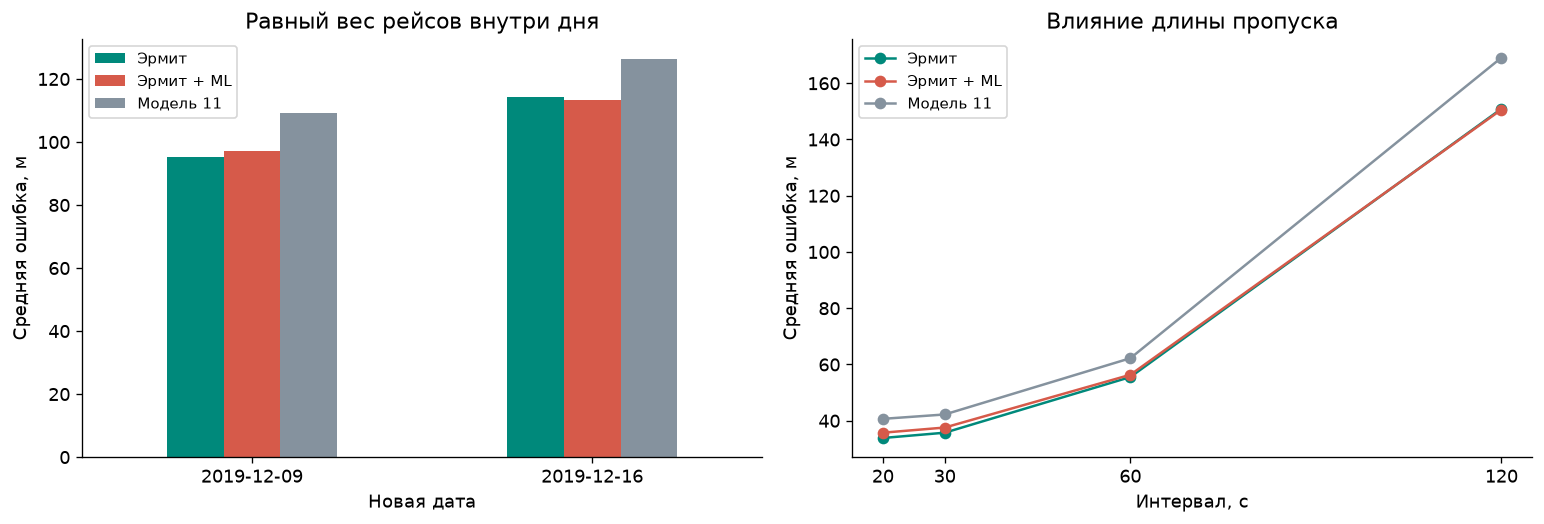

,day,flight_id,turn_group,tasks,hermite_mean_m,model_mean_m,fraction_worse
0,2019-12-09,DLH9CK_5308,До 5°,429,59.005,53.840,0.361
1,2019-12-09,DLH9CK_5308,5–15°,110,150.193,155.445,0.645
2,2019-12-09,DLH9CK_5308,Более 15°,440,220.436,213.386,0.425
3,2019-12-09,EZY61VB_35740,До 5°,528,59.575,58.263,0.441
4,2019-12-09,EZY61VB_35740,5–15°,143,166.900,166.029,0.503
5,2019-12-09,EZY61VB_35740,Более 15°,176,393.884,382.605,0.500
6,2019-12-09,EZY85VA_22895,До 5°,429,72.785,78.797,0.657
7,2019-12-09,EZY85VA_22895,5–15°,363,136.834,137.965,0.529
8,2019-12-09,EZY85VA_22895,Более 15°,231,319.793,327.788,0.571
9,2019-12-09,EZY89KP_37985,До 5°,935,40.897,45.658,0.678


,hermite_mean_m,model_mean_m,fraction_worse
turn_group,,,
До 5°,57.859,58.549,0.517
5–15°,158.262,164.593,0.608
Более 15°,337.446,334.371,0.510


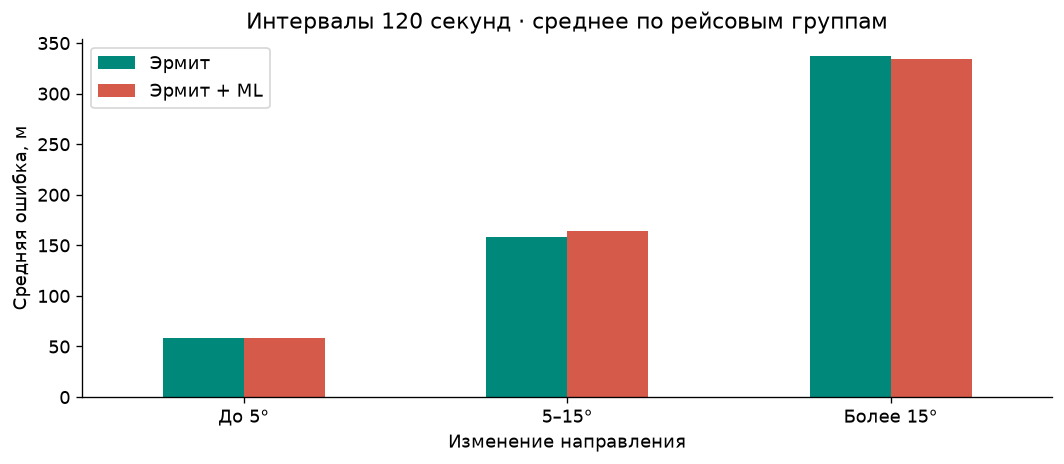

**Новые даты вместе:** Эрмит 105.3 м → Эрмит + ML 105.7 м; изменение в пользу ML **-0.3%**. Средняя рейсовая доля целей с ухудшением: **53.2%**.

417

In [7]:
# Разделяем общий результат по длине пропуска и по новой дате
by_gap = evaluation.groupby(['day','flight_id','gap_s','method']).error_m.mean().reset_index()
gap = by_gap.groupby(['gap_s','method']).error_m.mean().unstack()
display(gap.round(2))
labels = {'hermite':'Эрмит','hermite_ml':'Эрмит + ML','ridge_11':'Модель 11'}
colors = {'hermite':'#00897B','hermite_ml':'#D65A4A','ridge_11':'#85929E'}
fig,axes = plt.subplots(1,2,figsize=(13,4.5))
day_table = summary[summary.method.isin(labels)].groupby(['day','method']).mean_m.mean().unstack()
day_table.rename(columns=labels).plot.bar(ax=axes[0],color=[colors[m] for m in day_table.columns])
axes[0].set(xlabel='Новая дата',ylabel='Средняя ошибка, м',title='Равный вес рейсов внутри дня')
axes[0].tick_params(axis='x',rotation=0)
axes[0].legend(fontsize=9)
for method in labels:
    axes[1].plot(gap.index,gap[method],'o-',color=colors[method],label=labels[method])
axes[1].set(xlabel='Интервал, с',ylabel='Средняя ошибка, м',title='Влияние длины пропуска',xticks=gap.index)
axes[1].legend(fontsize=9)
plt.tight_layout()
fig.savefig(study/'figures/12_hermite_correction.png',dpi=180)
plt.show()
# Присоединяем только диагностический показатель направления
diag = baseline_errors[baseline_errors.method.eq('linear_lat_lon')]
paired = paired.merge(diag[key+['endpoint_heading_change_deg']],on=key,validate='one_to_one')
paired['turn_group'] = pd.cut(paired.endpoint_heading_change_deg,[-.001,5,15,180],
                            labels=['До 5°','5–15°','Более 15°'])
turn = paired[paired.gap_s.eq(120)].groupby(['day','flight_id','turn_group'],observed=True).agg(
    tasks=('worse','size'),hermite_mean_m=('hermite','mean'),model_mean_m=('hermite_ml','mean'),
    fraction_worse=('worse','mean')).reset_index()
display(turn.round(3))
turn_macro = turn.groupby('turn_group',observed=True)[['hermite_mean_m','model_mean_m','fraction_worse']].mean()
display(turn_macro.round(3))
ax = turn_macro[['hermite_mean_m','model_mean_m']].rename(columns={
    'hermite_mean_m':'Эрмит','model_mean_m':'Эрмит + ML'}).plot.bar(color=['#00897B','#D65A4A'],figsize=(9,4))
ax.set(xlabel='Изменение направления',ylabel='Средняя ошибка, м',title='Интервалы 120 секунд · среднее по рейсовым группам')
ax.tick_params(axis='x',rotation=0)
plt.tight_layout()
plt.show()
# Сохраняем краткие итоги и полные ошибки независимо от знака улучшения
base = float(macro.loc['hermite','mean_m'])
learned = float(macro.loc['hermite_ml','mean_m'])
improvement = 100*(base-learned)/base
fractions = paired.groupby(['day','flight_id']).worse.mean()
display(Markdown(f'**Новые даты вместе:** Эрмит {base:.1f} м → Эрмит + ML {learned:.1f} м; '
                 f'изменение в пользу ML **{improvement:+.1f}%**. '
                 f'Средняя рейсовая доля целей с ухудшением: **{100*fractions.mean():.1f}%**.'))
assert hashlib.sha256(model11_path.read_bytes()).hexdigest() == plan['model11_sha256']
summary.to_csv(study/'reports/12_test_by_flight.csv',index=False)
macro.to_csv(study/'reports/12_test_macro.csv')
per_day.to_csv(study/'reports/12_test_by_day.csv')
gap.to_csv(study/'reports/12_test_by_gap.csv')
turn.to_csv(study/'reports/12_test_by_turn.csv',index=False)
fractions.to_csv(study/'reports/12_fraction_worse.csv')
evaluation.to_csv(study/'data/hermite_validation/12_test_errors.csv',index=False)
pd.DataFrame(provenance).to_csv(study/'reports/12_data_inventory.csv',index=False)
result = {'test_days':plan['test_days'],'train_flights':int(tasks.loc[train_mask,'flight_id'].nunique()),
          'validation_flights':int(tasks.loc[val_mask,'flight_id'].nunique()),
          'test_flights':int(tasks.loc[test_mask,'flight_id'].nunique()),'test_tasks':int(test_mask.sum()),
          'alpha':alpha,'hermite_mean_m':base,'hermite_ml_mean_m':learned,
          'model11_mean_m':float(macro.loc['ridge_11','mean_m']),
          'improvement_percent':improvement,'macro_fraction_worse':float(fractions.mean()),
          'model11_unchanged':True}
(study/'reports/12_hermite_audit.json').write_text(json.dumps(result,ensure_ascii=False,indent=2)+'\n',encoding='utf8')

## Границы вывода

Поправка оценена на двух новых датах без их использования для настройки. Это все еще близкие аэропорты, часы и тот же источник. Validation уже применялась в 11 и является частью разработки. Разделение выполнено по датам и полетам, не по бортам.

Окна перекрываются; отдельные цели не независимы. Число рейсов ограничено, статистическая значимость не оценивалась. Преимущество или ухудшение относится к текущей модели с 19 признаками, а не к любым методам ML. При ухудшении нельзя объявлять поправку предпочтительной или исключать неудобные случаи.

Ответы – наблюдения OpenSky, не независимое истинное положение. Расхождение 43 км остается отдельной задачей. Любая дальнейшая настройка после просмотра этих дат потребует следующего проверочного набора.